In [1]:
import pandas as pd

data = {
    "Income": [25000, 50000, 30000, 80000, 45000,
               90000, 20000, 60000, 75000, 35000,
               100000, 40000, 55000, 28000, 70000,
               85000, 32000, 65000, 48000, 95000],

    "Credit_Score": [550, 750, 600, 800, 700,
                     820, 500, 760, 790, 620,
                     850, 680, 720, 530, 780,
                     810, 610, 770, 690, 830],

    "Loan_Amount": [200000, 150000, 180000, 200000, 120000,
                    250000, 180000, 160000, 220000, 150000,
                    300000, 130000, 170000, 190000, 210000,
                    240000, 140000, 180000, 160000, 280000],

    "Loan_Approved": [0, 1, 0, 1, 1,
                      1, 0, 1, 1, 0,
                      1, 1, 1, 0, 1,
                      1, 0, 1, 1, 1]
}

df = pd.DataFrame(data)

print(df.head())
print(df.shape)

   Income  Credit_Score  Loan_Amount  Loan_Approved
0   25000           550       200000              0
1   50000           750       150000              1
2   30000           600       180000              0
3   80000           800       200000              1
4   45000           700       120000              1
(20, 4)


C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\Admin\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:
# Step 2: Separate Features (X) and Target (y).
X = df[["Income", "Credit_Score", "Loan_Amount"]]
y = df["Loan_Approved"]
print(X.head())
print(y.head())


   Income  Credit_Score  Loan_Amount
0   25000           550       200000
1   50000           750       150000
2   30000           600       180000
3   80000           800       200000
4   45000           700       120000
0    0
1    1
2    0
3    1
4    1
Name: Loan_Approved, dtype: int64


In [3]:
# Step 3 : Spilt the data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 16
Testing rows: 4


In [4]:
# Training Random Forest Model.
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100, # Uses 100 decision trees
    random_state=42
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [5]:
# Lets check our trained data on test data.
y_pred = model.predict(X_test) # asks the model to predict whether each test applicant's loan will be approved.

print("Actual results:")
print(y_test.values) # contains the actual outcomes.

print("Predicted results:")
print(y_pred) # contains the model's predictions
# 1 means approved and 0 means rejected.

Actual results:
[1 0 1 1]
Predicted results:
[1 0 1 1]


Suppose our model predicts that an applicant's loan should be approved.

SHAP helps us investigate how the applicant's income, credit score, and loan amount contributed to that prediction.

In [7]:
# # Import SHAP - SHapley Additive exPlanations


import numpy as np
import shap

print("NumPy:", np.__version__)
print("SHAP:", shap.__version__)

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")

NumPy: 1.26.4
SHAP: 0.45.1
SHAP values calculated successfully!


In [8]:
# Import SHAP - SHapley Additive exPlanations

# Think of the explainer as a tool that investigates how the model makes predictions.
explainer = shap.TreeExplainer(model)

# Calculates the contribution of each feature to the model's predictions for our test samples.
shap_values = explainer.shap_values(X_test)

print("SHAP values calculated successfully!")
print("Test data shape:", X_test.shape)
print("SHAP values shape:", shap_values.shape)

SHAP values calculated successfully!
Test data shape: (4, 3)
SHAP values shape: (4, 3, 2)


What does (4, 3, 2) mean?
- 4 → Four test applicants.
- 3 → Three features: Income, Credit_Score, and Loan_Amount.
- 2 → Two classes: Loan Rejected (0) and Loan Approved (1).

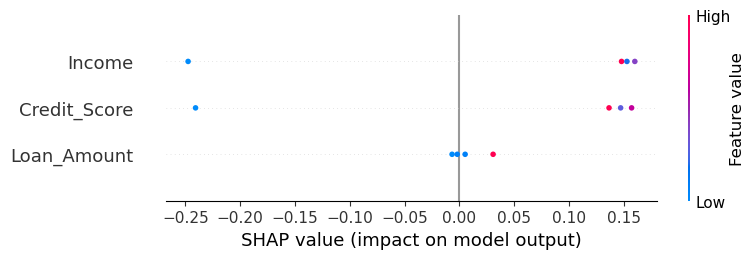

In [10]:
# Next step: Visualize the SHAP values
import matplotlib.pyplot as plt

shap.summary_plot(
    shap_values[:, :, 1],
    X_test,
    feature_names=X_test.columns
)

In [11]:
results = X_test.copy()

results["Actual_Result"] = y_test
results["Predicted_Result"] = y_pred

results["Actual_Result"] = results["Actual_Result"].map({
    0: "Rejected",
    1: "Approved"
})

results["Predicted_Result"] = results["Predicted_Result"].map({
    0: "Rejected",
    1: "Approved"
})

print(results)
# The output shows who were approved or rejected for the loan with the aspect of their features.

    Income  Credit_Score  Loan_Amount Actual_Result Predicted_Result
10  100000           850       300000      Approved         Approved
9    35000           620       150000      Rejected         Rejected
18   48000           690       160000      Approved         Approved
7    60000           760       160000      Approved         Approved


I'll select one applicant and use SHAP to understand why the model predicted approval or rejection for that specific person.

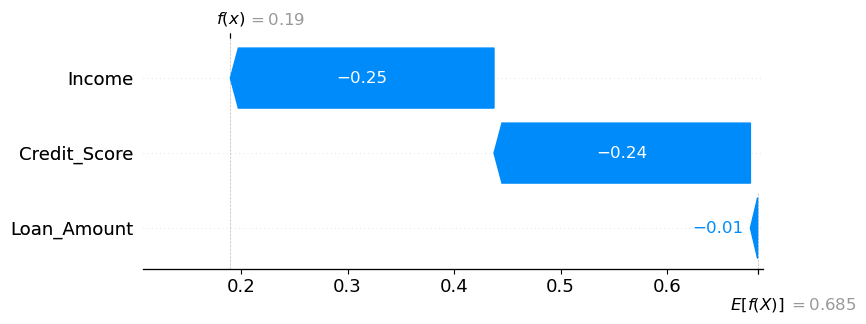

In [23]:
# Create a SHAP waterfall plot
# Select Applicant 9 from the test data
applicant_index = X_test.index.get_loc(9)

# Get SHAP values for this applicant
applicant_shap = shap_values[applicant_index, :, 1]

# Plot the explanation
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value[1],
    applicant_shap,
    feature_names=X_test.columns.tolist()
)

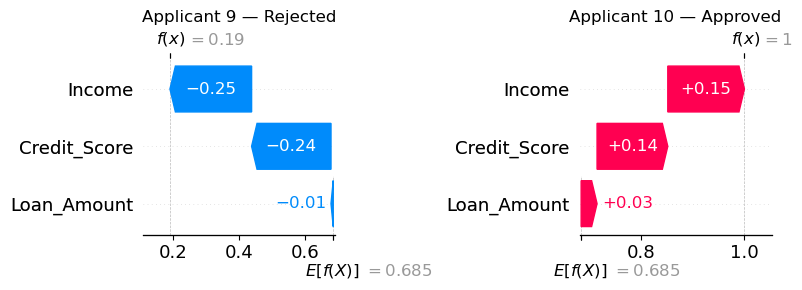

In [25]:
# Compare applicants :
import matplotlib.pyplot as plt

# Find each applicant's position in the test dataset
rejected_position = X_test.index.get_loc(9)
approved_position = X_test.index.get_loc(10)

# Get SHAP values for the approved class (1)
rejected_shap = shap_values[rejected_position, :, 1]
approved_shap = shap_values[approved_position, :, 1]

# Create two individual SHAP waterfall plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plt.sca(axes[0])
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value[1],
    rejected_shap,
    feature_names=X_test.columns.tolist(),
    show=False
)
axes[0].set_title("Applicant 9 — Rejected")

plt.sca(axes[1])
shap.plots._waterfall.waterfall_legacy(
    explainer.expected_value[1],
    approved_shap,
    feature_names=X_test.columns.tolist(),
    show=False
)
axes[1].set_title("Applicant 10 — Approved")

plt.tight_layout()
plt.show()